# VAE for Tabular Data Generation
Building a Variational Autoencoder from scratch in PyTorch

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

torch.manual_seed(42)
np.random.seed(42)

df = pd.read_csv('../data/adult_clean.csv')
print('Shape:', df.shape)

Shape: (32561, 15)


In [2]:
# Preprocessing — same as GAN
df_enc = df.copy()
cat_cols = df.select_dtypes(include='object').columns.tolist()
num_cols = df.select_dtypes(include='number').columns.tolist()

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))
    encoders[col] = le

scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_enc),
    columns=df_enc.columns
)

data_tensor = torch.FloatTensor(df_scaled.values)
print('Tensor shape:', data_tensor.shape)

Tensor shape: torch.Size([32561, 15])


In [3]:
# VAE architecture
INPUT_DIM = data_tensor.shape[1]
HIDDEN_DIM = 256
LATENT_DIM = 64

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.enc2 = nn.Linear(HIDDEN_DIM, HIDDEN_DIM)
        self.mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.log_var = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        # Decoder
        self.dec1 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.dec2 = nn.Linear(HIDDEN_DIM, HIDDEN_DIM)
        self.dec3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.enc1(x))
        h = F.relu(self.enc2(h))
        return self.mu(h), self.log_var(h)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = F.relu(self.dec1(z))
        h = F.relu(self.dec2(h))
        return torch.sigmoid(self.dec3(h))

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        return self.decode(z), mu, log_var

vae = VAE()
print('VAE params:', sum(p.numel() for p in vae.parameters()))

VAE params: 189071


In [4]:
# VAE loss = reconstruction loss + KL divergence
def vae_loss(recon, x, mu, log_var):
    recon_loss = F.mse_loss(recon, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return recon_loss + kl_loss

EPOCHS = 300
BATCH_SIZE = 256
LR = 0.001

optimizer = torch.optim.Adam(vae.parameters(), lr=LR)
dataset = torch.utils.data.TensorDataset(data_tensor)
loader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

losses = []
for epoch in range(EPOCHS):
    total_loss = 0
    for (batch,) in loader:
        optimizer.zero_grad()
        recon, mu, log_var = vae(batch)
        loss = vae_loss(recon, batch, mu, log_var)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(df)
    losses.append(avg_loss)
    if (epoch+1) % 50 == 0:
        print(f'Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.4f}')

print('Training complete!')

Epoch 50/300 | Loss: 0.9431


Epoch 100/300 | Loss: 0.9426


Epoch 150/300 | Loss: 0.9425


Epoch 200/300 | Loss: 0.9424


Epoch 250/300 | Loss: 0.9424


Epoch 300/300 | Loss: 0.9425
Training complete!


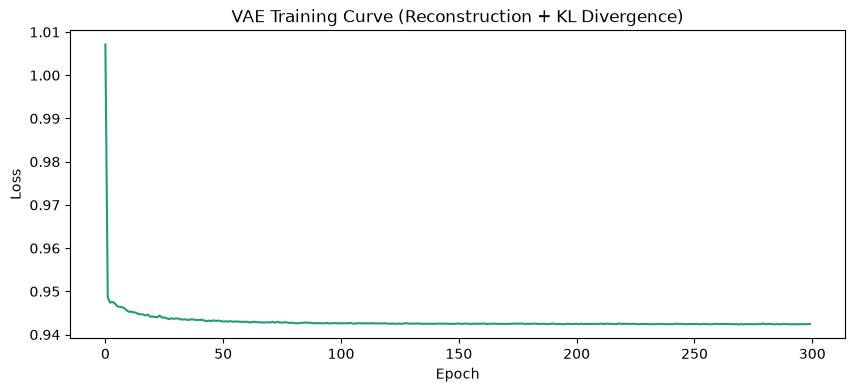

In [5]:
# Plot training curve
plt.figure(figsize=(10, 4))
plt.plot(losses, color='#1D9E75')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('VAE Training Curve (Reconstruction + KL Divergence)')
plt.savefig('../data/vae_training.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Generate synthetic data
vae.eval()
with torch.no_grad():
    z = torch.randn(len(df), LATENT_DIM)
    synthetic_scaled = vae.decode(z).numpy()

synthetic_raw = scaler.inverse_transform(synthetic_scaled)
synthetic_df = pd.DataFrame(synthetic_raw, columns=df_enc.columns)

for col in cat_cols:
    synthetic_df[col] = synthetic_df[col].round().astype(int).clip(
        0, len(encoders[col].classes_)-1
    )
    synthetic_df[col] = encoders[col].inverse_transform(synthetic_df[col])

synthetic_df.to_csv('../data/synthetic_vae.csv', index=False)
torch.save(vae.state_dict(), '../models/vae.pt')
print('VAE synthetic data saved:', synthetic_df.shape)
synthetic_df.head()

VAE synthetic data saved: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,38.699051,Private,192377.109375,Doctorate,10.096047,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,1093.493774,90.823540,40.338825,Thailand,0.244880
1,38.608898,Private,188544.515625,Doctorate,10.109128,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,916.773804,79.822151,40.300140,Thailand,0.241437
2,38.585197,Private,190382.953125,Doctorate,10.109650,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,1061.227661,87.852531,40.279552,Thailand,0.241105
3,38.539265,Private,188432.484375,Doctorate,10.115641,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,956.287048,81.522049,40.252689,Thailand,0.239308
4,38.572891,Private,189485.687500,Doctorate,10.165402,Married-spouse-absent,Machine-op-inspct,Not-in-family,White,Male,1067.464478,86.276367,40.315571,Thailand,0.238729
